In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/cleaned_housing.csv")
df.shape

(250000, 29)

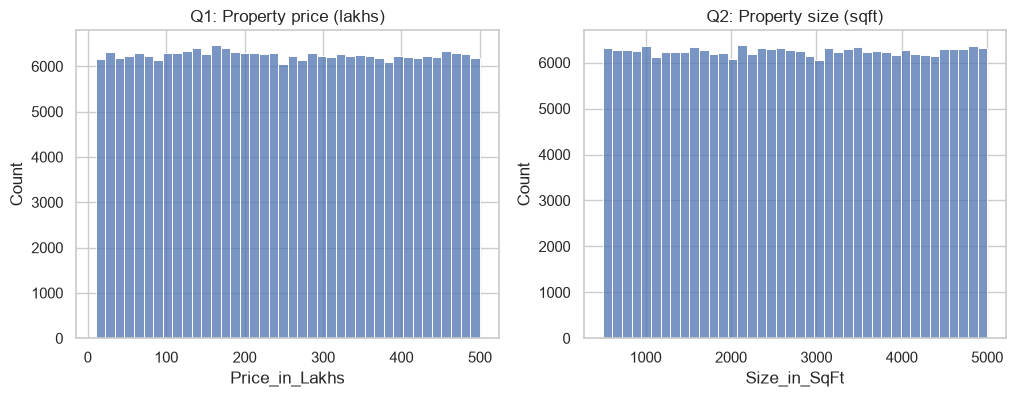

In [ ]:
# Q1 and Q2: How are prices and sizes distributed?
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price_in_Lakhs"], bins=40, ax=ax[0])
ax[0].set_title("Q1: Property price (lakhs)")
sns.histplot(df["Size_in_SqFt"], bins=40, ax=ax[1])
ax[1].set_title("Q2: Property size (sqft)")
plt.show()

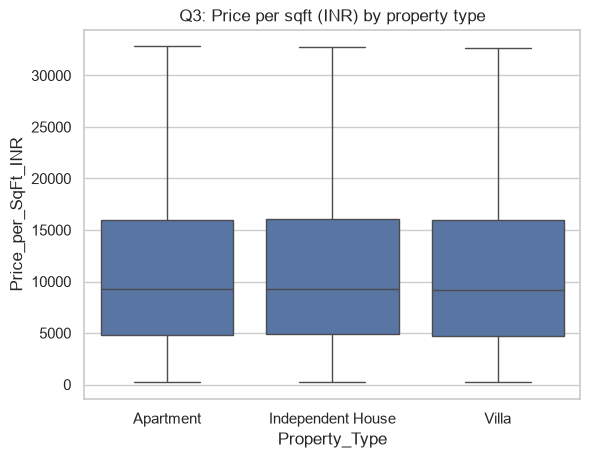

Property_Type
Apartment            9245.0
Independent House    9305.0
Villa                9190.0
Name: Price_per_SqFt_INR, dtype: float64


In [6]:
# Q3: How does price per sqft differ by property type?
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt_INR", showfliers=False)
plt.title("Q3: Price per sqft (INR) by property type")
plt.show()

print(df.groupby("Property_Type")["Price_per_SqFt_INR"].median().round(0))

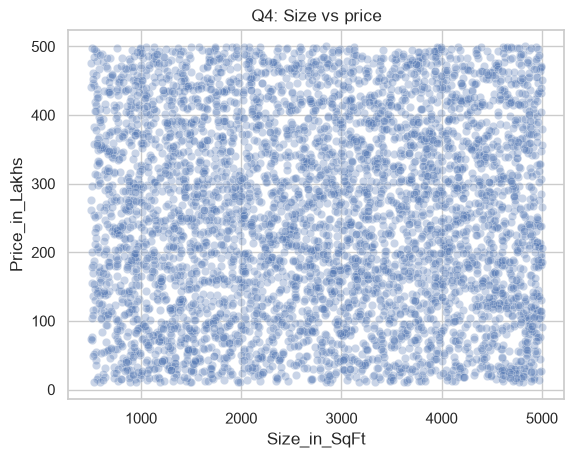

Correlation: -0.003


In [8]:
# Q4: Is there a relationship between size and price?
sample = df.sample(5000, random_state=42)   # 250,000 dots would be slow and unreadable
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3)
plt.title("Q4: Size vs price")
plt.show()

print("Correlation:", round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 3))

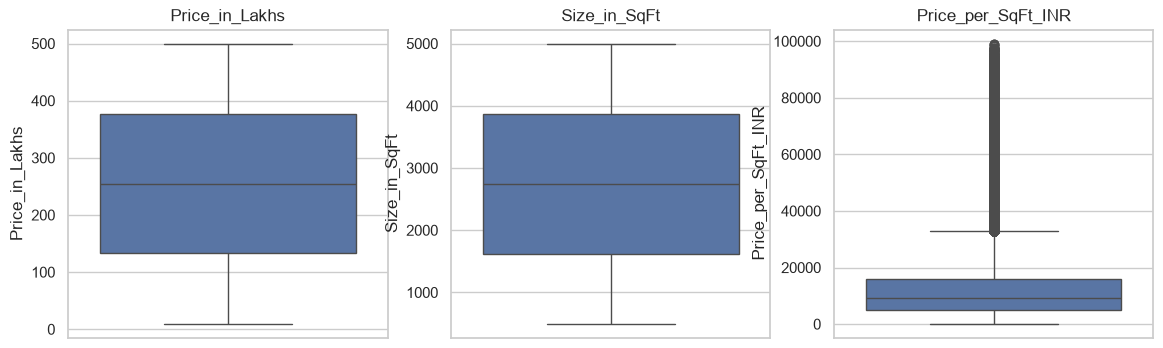

Price_in_Lakhs: 0 outliers (0.0%)
Size_in_SqFt: 0 outliers (0.0%)
Price_per_SqFt_INR: 19723 outliers (7.9%)


In [9]:
# Q5: Where are the outliers?
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col in zip(ax, ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_INR"]):
    sns.boxplot(y=df[col], ax=a)
    a.set_title(col)
plt.show()

for col in ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_INR"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n} outliers ({n / len(df) * 100:.1f}%)")

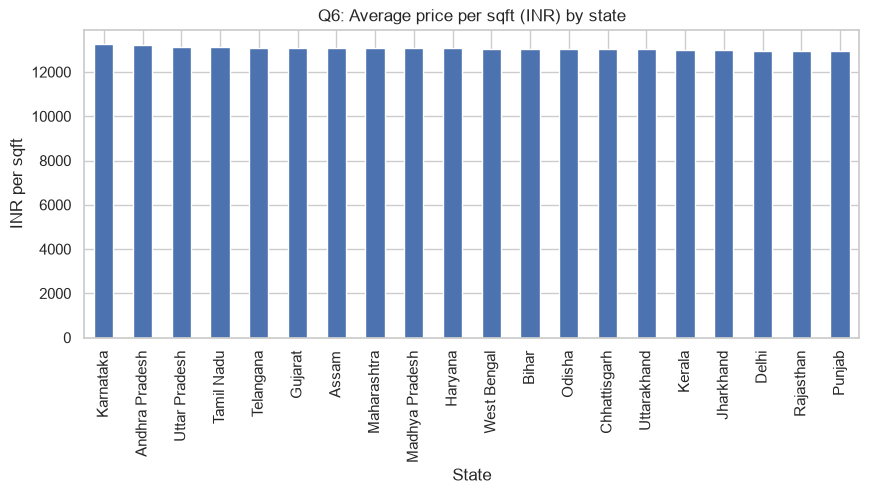

State
Karnataka         13252.0
Andhra Pradesh    13202.0
Uttar Pradesh     13143.0
Tamil Nadu        13132.0
Telangana         13093.0
Name: Price_per_SqFt_INR, dtype: float64


In [10]:
# Q6: Average price per sqft by state
state_ppsf = df.groupby("State")["Price_per_SqFt_INR"].mean().sort_values(ascending=False)
state_ppsf.plot(kind="bar", figsize=(10, 4))
plt.title("Q6: Average price per sqft (INR) by state")
plt.ylabel("INR per sqft")
plt.show()
print(state_ppsf.round(0).head())

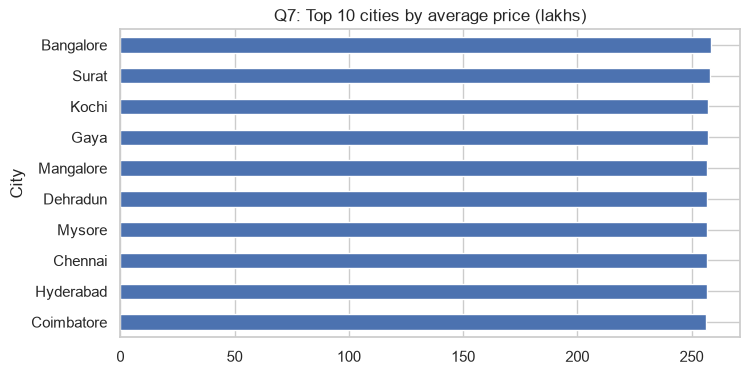

City
Bangalore    258.5
Surat        258.1
Kochi        257.4
Name: Price_in_Lakhs, dtype: float64 City
Cuttack    250.8
Name: Price_in_Lakhs, dtype: float64


In [11]:
# Q7: Average property price by city (top 10)
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)
city_price.head(10).plot(kind="barh", figsize=(8, 4))
plt.title("Q7: Top 10 cities by average price (lakhs)")
plt.gca().invert_yaxis()
plt.show()
print(city_price.head(3).round(1), city_price.tail(1).round(1))

Locality
Locality_72     21.0
Locality_403    21.0
Locality_90     20.0
Locality_491    20.0
Locality_99     20.0
Name: Age_of_Property, dtype: float64
Locality
Locality_54     17.0
Locality_63     17.0
Locality_60     17.0
Locality_10     17.0
Locality_443    16.0
Name: Age_of_Property, dtype: float64


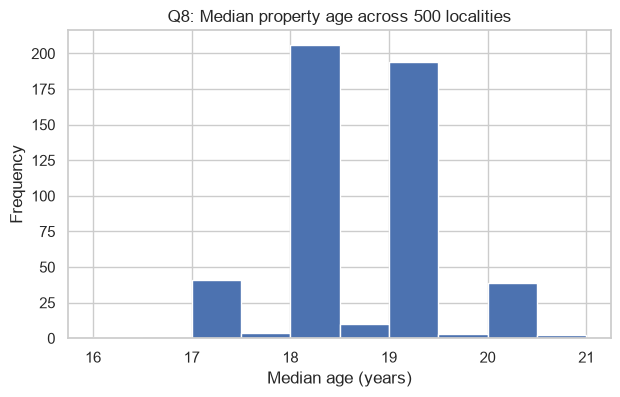

In [13]:
# Q8: Median property age by locality
loc_age = df.groupby("Locality")["Age_of_Property"].median().sort_values(ascending=False)
print(loc_age.head(5))
print(loc_age.tail(5))
loc_age.plot(kind="hist", bins=10, figsize=(7, 4))
plt.title("Q8: Median property age across 500 localities")
plt.xlabel("Median age (years)")
plt.show()

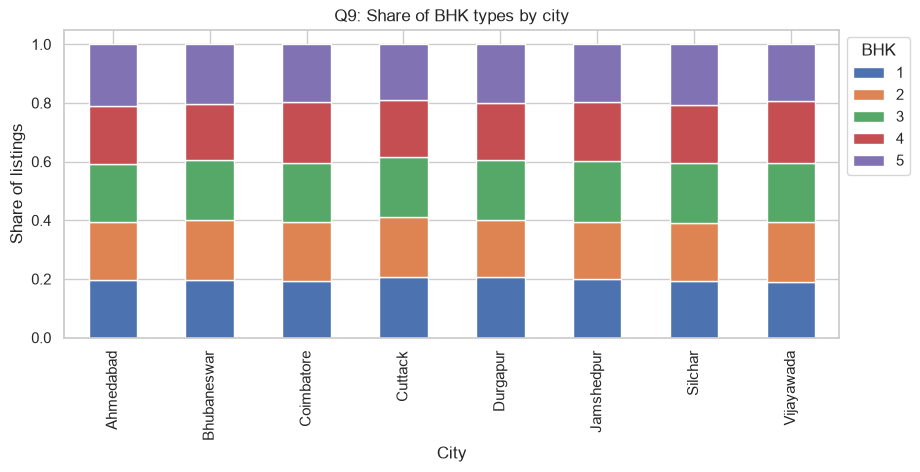

In [14]:
# Q9: BHK mix across the 8 busiest cities
top_cities = df["City"].value_counts().head(8).index
sub = df[df["City"].isin(top_cities)]
bhk_mix = pd.crosstab(sub["City"], sub["BHK"], normalize="index")
bhk_mix.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Q9: Share of BHK types by city")
plt.ylabel("Share of listings")
plt.legend(title="BHK", bbox_to_anchor=(1, 1))
plt.show()

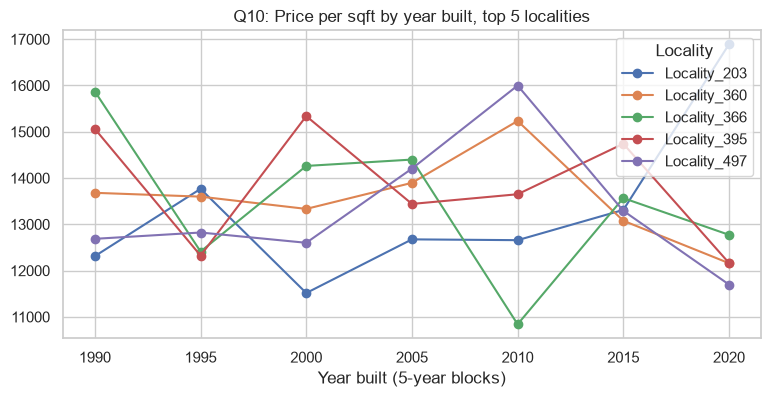

['Locality_395', 'Locality_366', 'Locality_497', 'Locality_360', 'Locality_203']


In [15]:
# Q10: Price per sqft trend in the 5 most expensive localities
top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().sort_values(ascending=False).head(5).index
sub = df[df["Locality"].isin(top5)].copy()
sub["Built_Decade_Half"] = (sub["Year_Built"] // 5 * 5)       # group years into 5-year blocks
trend = sub.groupby(["Built_Decade_Half", "Locality"])["Price_per_SqFt_INR"].mean().unstack()
trend.plot(marker="o", figsize=(9, 4))
plt.title("Q10: Price per sqft by year built, top 5 localities")
plt.xlabel("Year built (5-year blocks)")
plt.show()
print(top5.tolist())

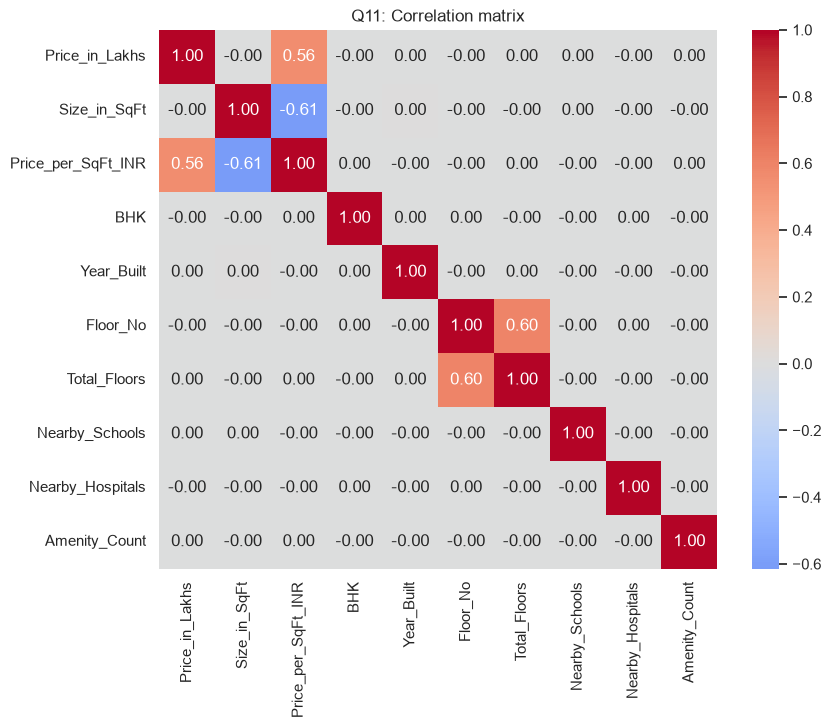

In [16]:
# Q11: Correlation matrix
cols = ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt_INR", "BHK", "Year_Built",
        "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals", "Amenity_Count"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Q11: Correlation matrix")
plt.show()

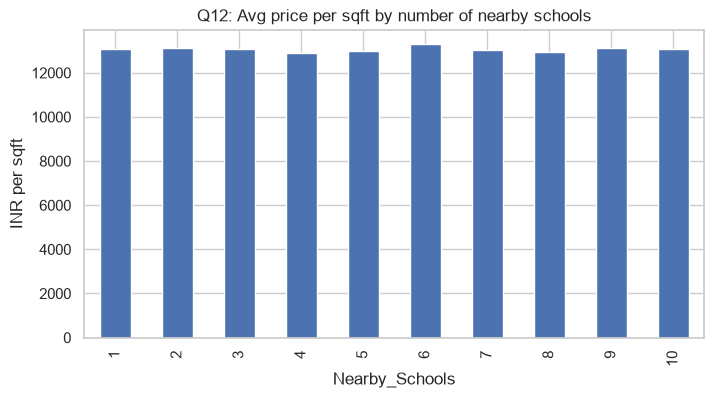

In [24]:
# Q12: Nearby schools and price per sqft
df.groupby("Nearby_Schools")["Price_per_SqFt_INR"].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Q12: Avg price per sqft by number of nearby schools")
plt.ylabel("INR per sqft")
plt.show()

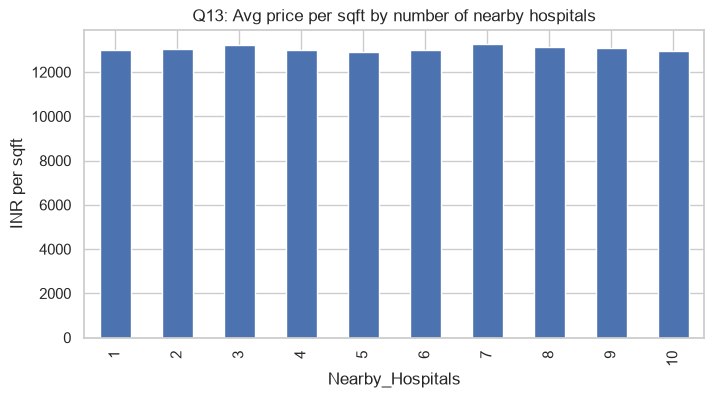

In [25]:
# Q13: Nearby hospitals and price per sqft
df.groupby("Nearby_Hospitals")["Price_per_SqFt_INR"].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Q13: Avg price per sqft by number of nearby hospitals")
plt.ylabel("INR per sqft")
plt.show()

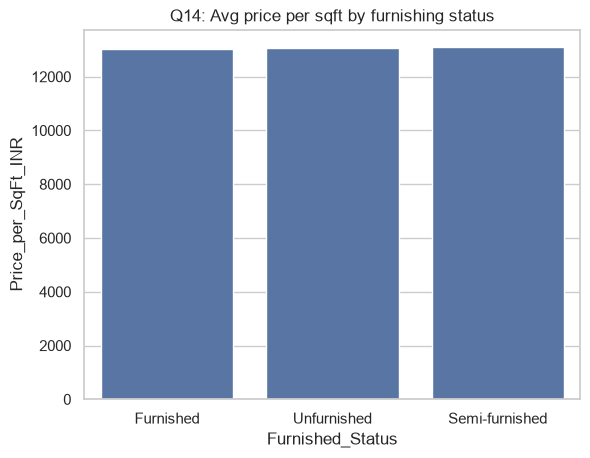

                     mean  median
Furnished_Status                 
Furnished         13034.0  9235.0
Semi-furnished    13093.0  9227.0
Unfurnished       13048.0  9283.0


In [26]:
# Q14: Furnishing status and price per sqft
sns.barplot(data=df, x="Furnished_Status", y="Price_per_SqFt_INR", errorbar=None)
plt.title("Q14: Avg price per sqft by furnishing status")
plt.show()
print(df.groupby("Furnished_Status")["Price_per_SqFt_INR"].agg(["mean", "median"]).round(0))

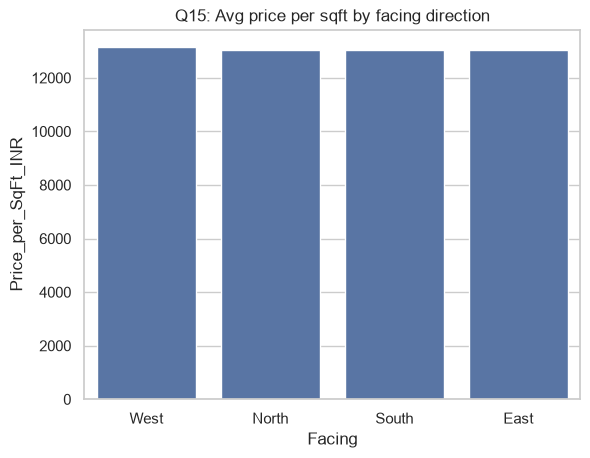

           mean  median
Facing                 
East    13024.0  9234.0
North   13025.0  9219.0
South   13044.0  9225.0
West    13140.0  9308.0


In [27]:
# Q15: Facing direction and price per sqft
sns.barplot(data=df, x="Facing", y="Price_per_SqFt_INR", errorbar=None)
plt.title("Q15: Avg price per sqft by facing direction")
plt.show()
print(df.groupby("Facing")["Price_per_SqFt_INR"].agg(["mean", "median"]).round(0))

In [28]:
proc = pd.read_csv("data/processed_housing.csv")
df["Good_Investment"] = proc["Good_Investment"]   # same row order, so this lines up

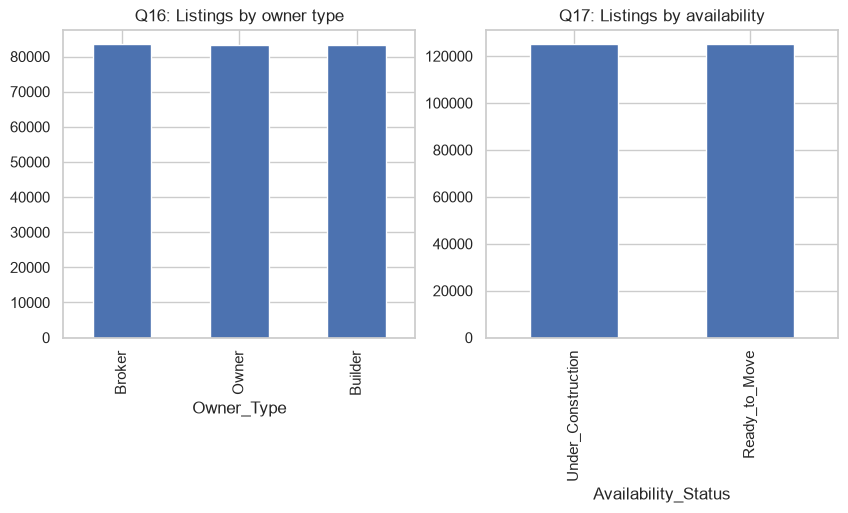

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64
Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64


In [29]:
# Q16 and Q17: Owner type and availability
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df["Owner_Type"].value_counts().plot(kind="bar", ax=ax[0], title="Q16: Listings by owner type")
df["Availability_Status"].value_counts().plot(kind="bar", ax=ax[1], title="Q17: Listings by availability")
plt.show()
print(df["Owner_Type"].value_counts())
print(df["Availability_Status"].value_counts())

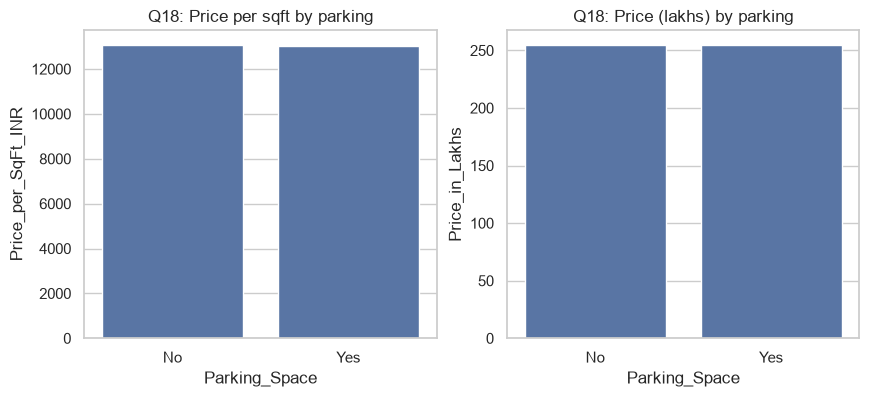

In [31]:
# Q18: Parking space and price
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x="Parking_Space", y="Price_per_SqFt_INR", errorbar=None, ax=ax[0])
sns.barplot(data=df, x="Parking_Space", y="Price_in_Lakhs", errorbar=None, ax=ax[1])
ax[0].set_title("Q18: Price per sqft by parking")
ax[1].set_title("Q18: Price (lakhs) by parking")
plt.show()

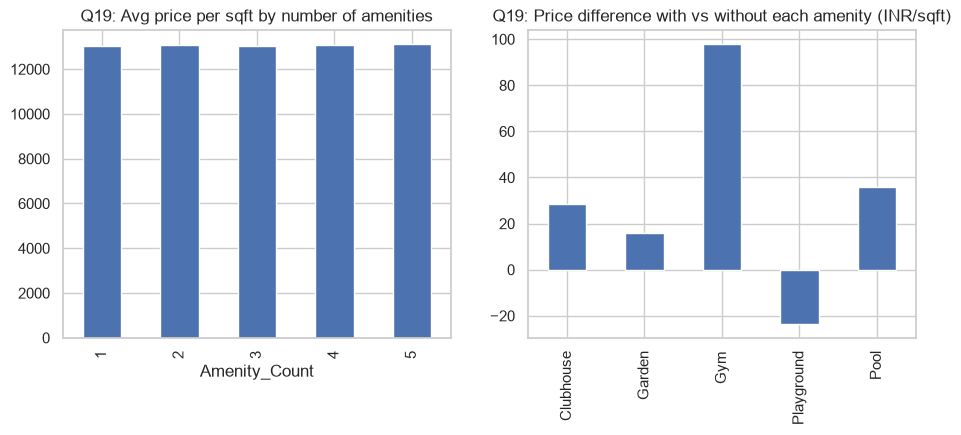

{'Clubhouse': 28, 'Garden': 16, 'Gym': 98, 'Playground': -23, 'Pool': 36}


In [33]:
# Q19: Amenities and price
amen = ["Has_Clubhouse", "Has_Garden", "Has_Gym", "Has_Playground", "Has_Pool"]
effect = {a.replace("Has_", ""): df[df[a] == 1]["Price_per_SqFt_INR"].mean()
                               - df[df[a] == 0]["Price_per_SqFt_INR"].mean() for a in amen}

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby("Amenity_Count")["Price_per_SqFt_INR"].mean().plot(kind="bar", ax=ax[0],
    title="Q19: Avg price per sqft by number of amenities")
pd.Series(effect).plot(kind="bar", ax=ax[1], title="Q19: Price difference with vs without each amenity (INR/sqft)")
plt.show()
print({k: round(v) for k, v in effect.items()})

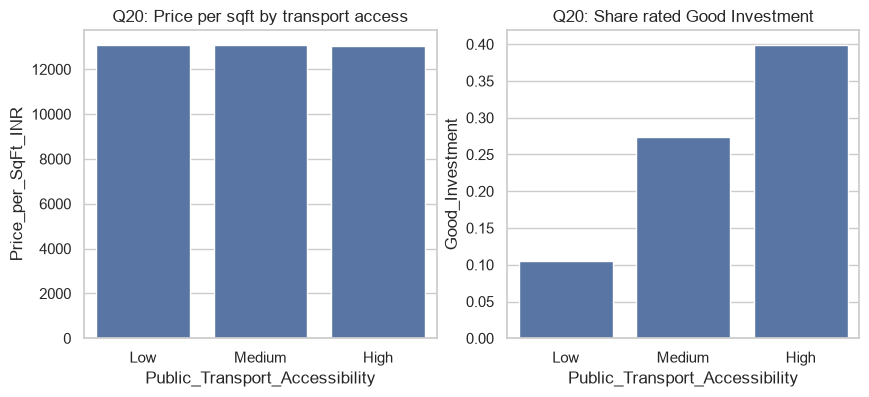

Public_Transport_Accessibility
High      0.399
Low       0.105
Medium    0.274
Name: Good_Investment, dtype: float64


In [35]:
# Q20: Public transport and investment potential
order = ["Low", "Medium", "High"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Price_per_SqFt_INR", order=order, errorbar=None, ax=ax[0])
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Good_Investment", order=order, errorbar=None, ax=ax[1])
ax[0].set_title("Q20: Price per sqft by transport access")
ax[1].set_title("Q20: Share rated Good Investment")
plt.show()
print(df.groupby("Public_Transport_Accessibility")["Good_Investment"].mean().round(3))